In [33]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
df.head(10)

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A
5,6,Identify the correct statement: What is the ef...,"An electric field, precisely aligned with the ...","A magnetic field, randomly aligned with the sp...","A magnetic field, precisely aligned with the s...","A gravitational field, randomly aligned with t...","A gravitational field, precisely aligned with ...",C
6,7,"Which of the following is correct? What is a ""...",A type of coffee that is made by boiling coffe...,A pattern left by a particle-laden liquid afte...,A type of coffee that is made by mixing instan...,A type of coffee that is made by pouring hot w...,A pattern left by a particle-laden liquid afte...,E
7,8,Select the most accurate option: What is the L...,The Liouville density is a probability distrib...,The Liouville density is a quasiprobability di...,The Liouville density is a bounded probability...,The Liouville density is a probability distrib...,The Liouville density is a probability distrib...,A
8,9,Select the most accurate option: What are the ...,"They are unknown, but possibilities include la...",They are known to be black holes and Preon stars.,They are only MACHOs.,They are clusters of brown dwarfs.,They are new particles such as RAMBOs.,A
9,10,Which of the following is correct? What is the...,"The Wigner function W(x, p) is the Wigner tran...","The Wigner function W(x, p) is a source functi...","The Wigner function W(x, p) is the derivative ...","The Wigner function W(x, p) represents the Ham...","The Wigner function W(x, p) is the time deriva...",A


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [37]:
df.describe()

,id
count,2000.000000
mean,1000.500000
std,577.494589
min,1.000000
25%,500.750000
50%,1000.500000
75%,1500.250000
max,2000.000000


In [38]:
# check missing values
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64
Duplicate rows: 0


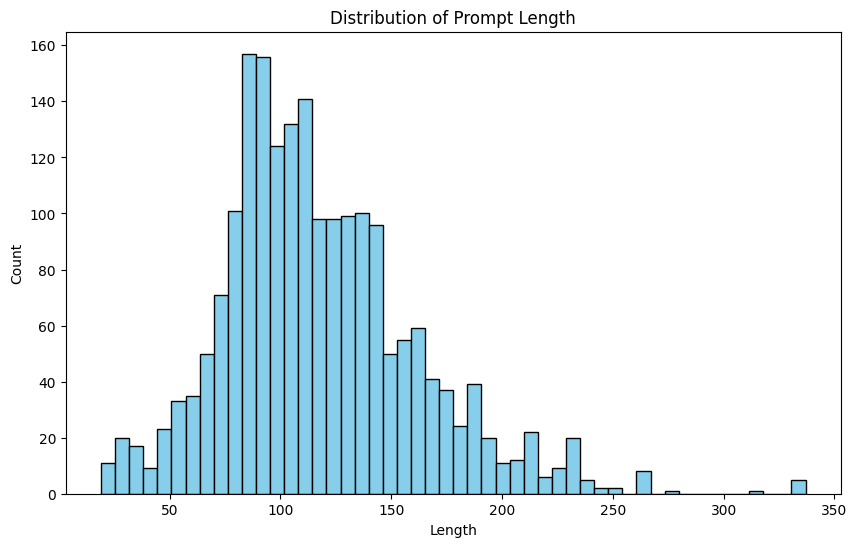

In [39]:
# no numeric columns in raw data, so creating length features
df['prompt_len'] = df['prompt'].str.len()
df['A_len'] = df['A'].str.len()
df['B_len'] = df['B'].str.len()

plt.figure(figsize=(10,6))
plt.hist(df['prompt_len'], bins=50, edgecolor='black', color='skyblue')
plt.title("Distribution of Prompt Length")
plt.xlabel("Length")
plt.ylabel("Count")
plt.show()

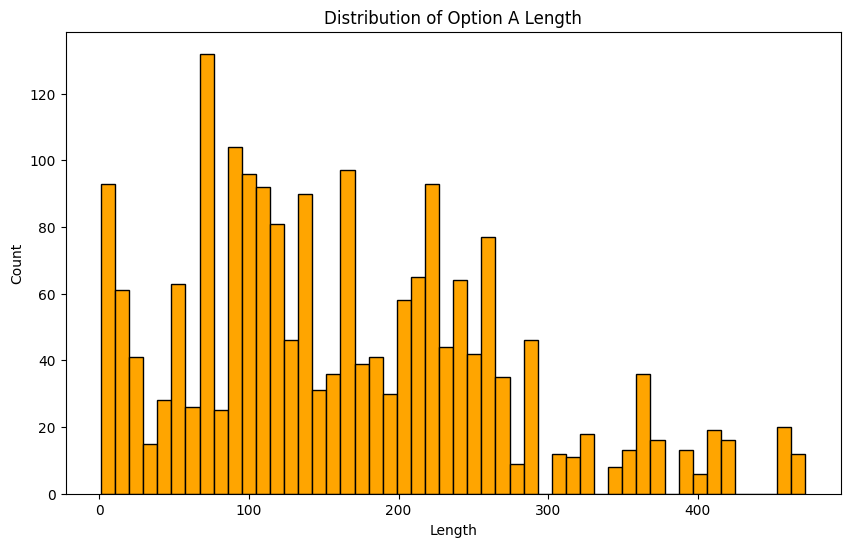

In [40]:
plt.figure(figsize=(10,6))
plt.hist(df['A_len'], bins=50, edgecolor='black', color='orange')
plt.title("Distribution of Option A Length")
plt.xlabel("Length")
plt.ylabel("Count")
plt.show()

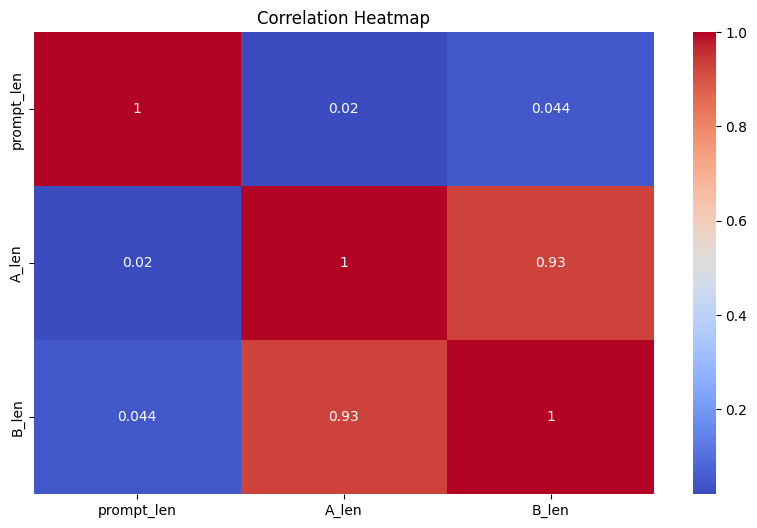

In [41]:
# correlation heatmap of length features
num_cols = df[['prompt_len', 'A_len', 'B_len']]
plt.figure(figsize=(10,6))
sns.heatmap(num_cols.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

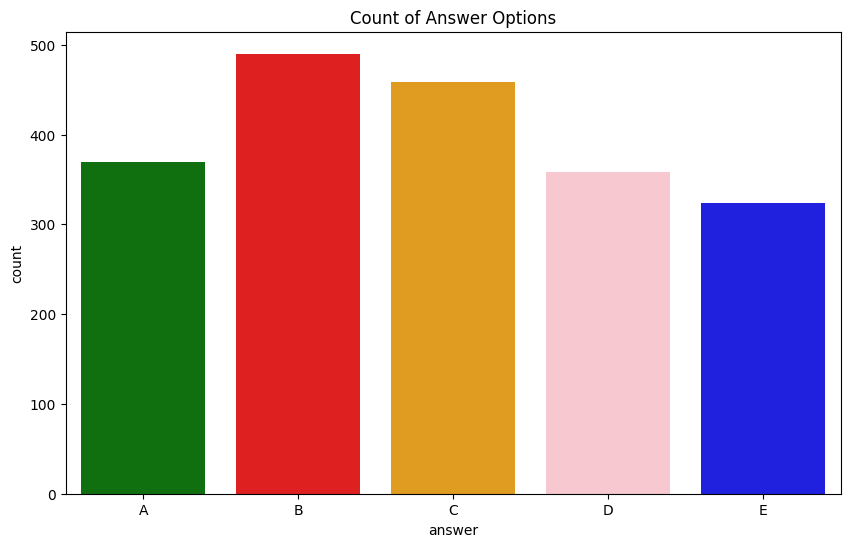

In [42]:
plt.figure(figsize=(10,6))
sns.countplot(x='answer', hue='answer', data=df, order=sorted(df['answer'].unique()), 
              palette=['red', 'green', 'orange', 'blue', 'pink'], legend=False)
plt.title("Count of Answer Options")
plt.show()

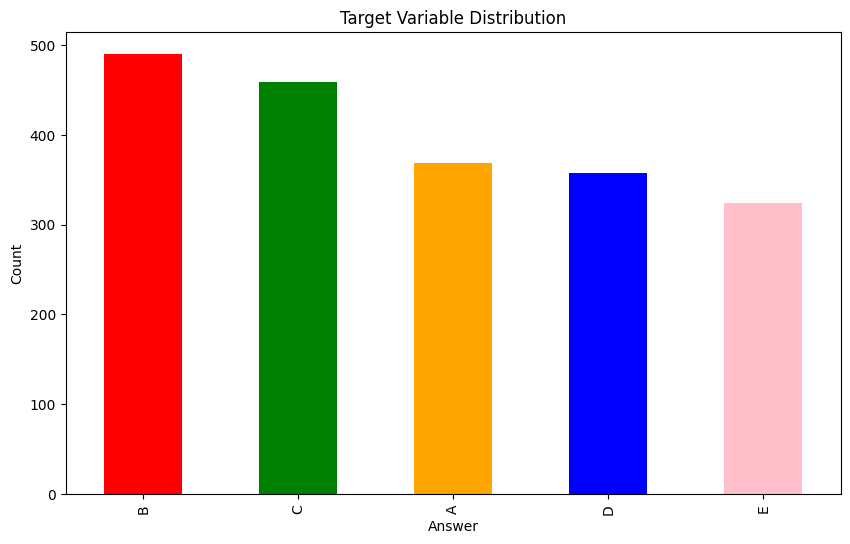

In [43]:
plt.figure(figsize=(10,6))
df['answer'].value_counts().plot(kind='bar', color=['red', 'green', 'orange', 'blue', 'pink'])
plt.title("Target Variable Distribution")
plt.xlabel("Answer")
plt.ylabel("Count")
plt.show()